# HDBSCAN

`t_hdbscan(...).fit()` partitions a torsional ensemble by density. The torsions are first
[preprocessed](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/torsion-preprocessing/): frames are compared with the symmetric distance
`d_sym`, the minimum over the symmetry operations, so two namings of one configuration are at
distance zero. Then:

```text
d_sym between the fitted frames -> HDBSCAN (min_cluster_size, min_samples) -> clusters 0, 1, ... by mass
every frame, fitted or not      -> its k nearest clustered frames vote (18 of 20)    -> cluster, -2 or -1
```

| parameter | default | what it sets | section |
|---|---|---|---|
| `mass_floor` | 0.01 | `min_cluster_size = ceil(mass_floor * n)`: the smallest cluster, as a fraction of the fitted frames | [2](#2-mass_floor-the-smallest-cluster) |
| `min_samples`, `min_samples_fraction` | `round(0.01 n)` | the core distance: the `min_samples`-th neighbour, which sets the density estimate | [3](#3-min_samples-the-density-estimate) |
| `allow_single_cluster` | False | whether the whole ensemble may come back as one cluster | [4](#4-allow_single_cluster) |
| `k`, `min_vote_fraction` | 20, 0.9 | the vote that assigns every frame after the fit | [5](#5-assigning-frames-k-and-min_vote_fraction) |
| `resampling`, `max_precomputed_frames` | False, 10 000 | more frames than the exact distance matrix allows | [6](#6-more-frames-than-the-matrix-allows-resampling) |
| the torsions passed | | the space the density is estimated in | [7](#7-which-torsions) |
| `symmetry`, `canonicalize`, `broken_by` | True, True, None | the preprocessing | [Torsion preprocessing](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/torsion-preprocessing/) |
| `seed`, `weights` | 5, None | the draw for `resampling`; frame weights (populations only, see below) | |

**The example** is alanine dipeptide, the 1 us cMD run of the [ALA tutorial](https://csy0000.github.io/MD-tools/tutorial/ALA/),
every 25th frame (4000 frames), on phi and psi, through the default symmetry-first route. The molecule is
built from the trajectory's own topology, so the atom mapping is the identity. Its only symmetry
operations exchange methyl hydrogens, which move neither phi nor psi: the descriptor has one operation,
and `d_sym` is the plain distance on the circle embedding.

**A cluster is a density basin, not a metastable state.** Nothing here looks at time.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[2] / "tutorial" / "_analysis"))   # docs/tutorial/_analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mdtraj as md
import tutorial_data as td
import md_tools
from md_tools.analysis import t_hdbscan, TorsionDefinitions, verify_atom_mapping
from rdkit import Chem

# Where the runs are is NOT printed: these pages are committed with their outputs.
print("tutorial runs:", "found" if td.runs_root().is_dir() else "MISSING", "| md-tools", md_tools.__version__)

tutorial runs: found | md-tools 0.6.5.2


In [2]:
traj = td.solute("ALA-1us")
mol = td.molecule_from_topology(traj)
mapping, why = verify_atom_mapping(mol, [(a.index, b.index) for a, b in traj.topology.bonds],
                                   [a.element.symbol for a in traj.topology.atoms])
phi_atoms, phi = md.compute_phi(traj)
psi_atoms, psi = md.compute_psi(traj)
QUADS, NAMES = (tuple(phi_atoms[0]), tuple(psi_atoms[0])), ("phi", "psi")
every = np.column_stack([phi[:, 0], psi[:, 0]])          # all 100 000 frames, radians
SUB = np.arange(0, len(every), 25)                       # the 4000 fitted frames
tors = every[SUB]
print(Chem.MolToSmiles(Chem.RemoveHs(mol)), "|", why)
print(f"{len(every)} frames in the run, {len(SUB)} fitted")

def fit(rows=SUB, cols=(0, 1), **kw):
    """t_hdbscan on the given frames and torsions, through the default symmetry-first route."""
    definitions = TorsionDefinitions(quads=tuple(QUADS[c] for c in cols), names=tuple(NAMES[c] for c in cols),
                                     indexing="zero-based", units="radian")
    return t_hdbscan(every[np.ix_(rows, cols)], molecule=mol, torsion_definitions=definitions,
                     coordinates=traj[rows], atom_mapping=mapping, **kw).fit()

def populations(f):
    s = f.summary()["settings"]
    return {"clusters": f.n_clusters_,
            "masses (%)": [round(100 * f.cluster_mass_[c], 1) for c in range(f.n_clusters_)],
            "noise -2 (%)": round(100 * f.noise_mass_, 2), "ambiguous -1 (%)": round(100 * f.ambiguous_mass_, 2),
            "min_cluster_size": s["min_cluster_size"], "min_samples": s["min_samples"]}

H, xe, ye = np.histogram2d(np.degrees(every[:, 0]), np.degrees(every[:, 1]), bins=72,
                           range=[[-180, 180], [-180, 180]])
F = -np.log(np.where(H > 0, H / H.sum(), np.nan)); F -= np.nanmin(F)

def rama(ax, f, title, rows=SUB):
    """The free energy of the whole run in grey, every fitted frame coloured by its label."""
    ax.pcolormesh(xe, ye, F.T, cmap="Greys_r", vmin=0, vmax=10, shading="auto", alpha=0.35)
    d = np.degrees(every[rows])
    for c in range(f.n_clusters_):
        m = f.labels_ == c
        ax.scatter(d[m, 0], d[m, 1], s=3, color=f"C{c % 10}", label=f"{c} ({100 * f.cluster_mass_[c]:.1f} %)")
    for code, colour, name in ((-2, "k", "noise"), (-1, "m", "ambiguous")):
        m = f.labels_ == code
        if m.any():
            ax.scatter(d[m, 0], d[m, 1], s=9, marker="x", color=colour, label=f"{name} ({m.sum()})")
    ax.set(xlim=(-180, 180), ylim=(-180, 180), xticks=[-180, -90, 0, 90, 180], yticks=[-180, -90, 0, 90, 180],
           xlabel="phi (deg)", ylabel="psi (deg)", title=title)
    ax.legend(fontsize=7, markerscale=2, loc="lower right")

CNC(=O)[C@H](C)NC(C)=O | identity verified: elements and the full bond graph agree under this mapping
100000 frames in the run, 4000 fitted


## 1. The default fit

`mass_floor=0.01` (clusters of at least 40 of the 4000 frames) and `min_samples` 40.

operations on phi and psi: 1


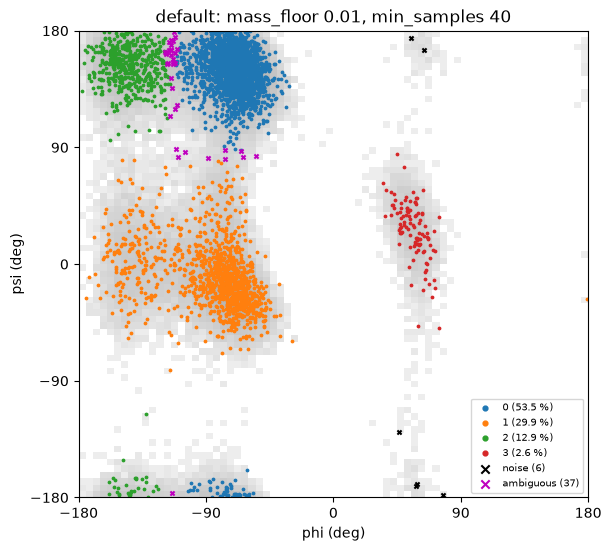

,clusters,masses (%),noise -2 (%),ambiguous -1 (%),min_cluster_size,min_samples
0,4,"[53.5, 29.9, 12.9, 2.6]",0.15,0.92,40,40


In [3]:
default = fit()
print("operations on phi and psi:", len(default.descriptor_.operations))
fig, ax = plt.subplots(figsize=(6, 5.4), layout="constrained")
rama(ax, default, "default: mass_floor 0.01, min_samples 40")
plt.show()
pd.DataFrame([populations(default)])

Four clusters: PPII (phi near -70, psi near 150), alpha-R, beta (phi near -150, psi near 150) and alpha-L. The
0.18 % strip at phi near 60, psi near 180 that the [torsion partitioning](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/torsion-partitioning/) separates is
below the 1 % floor and goes to noise or to its neighbour.

## 2. `mass_floor`: the smallest cluster

`min_cluster_size = ceil(mass_floor * n)`. **The floor is a mass, not a count**: a fraction asks the same
question at every dataset size, where an absolute count (the former default, 500 frames) loosens as the
ensemble grows: 0.17 % at 300 000 frames. A density basin under the floor is not a cluster; its frames
become noise or join the cluster their neighbours vote for. `min_samples` is held at 40 here, so only the
selection of clusters changes, not the density estimate (section 3).

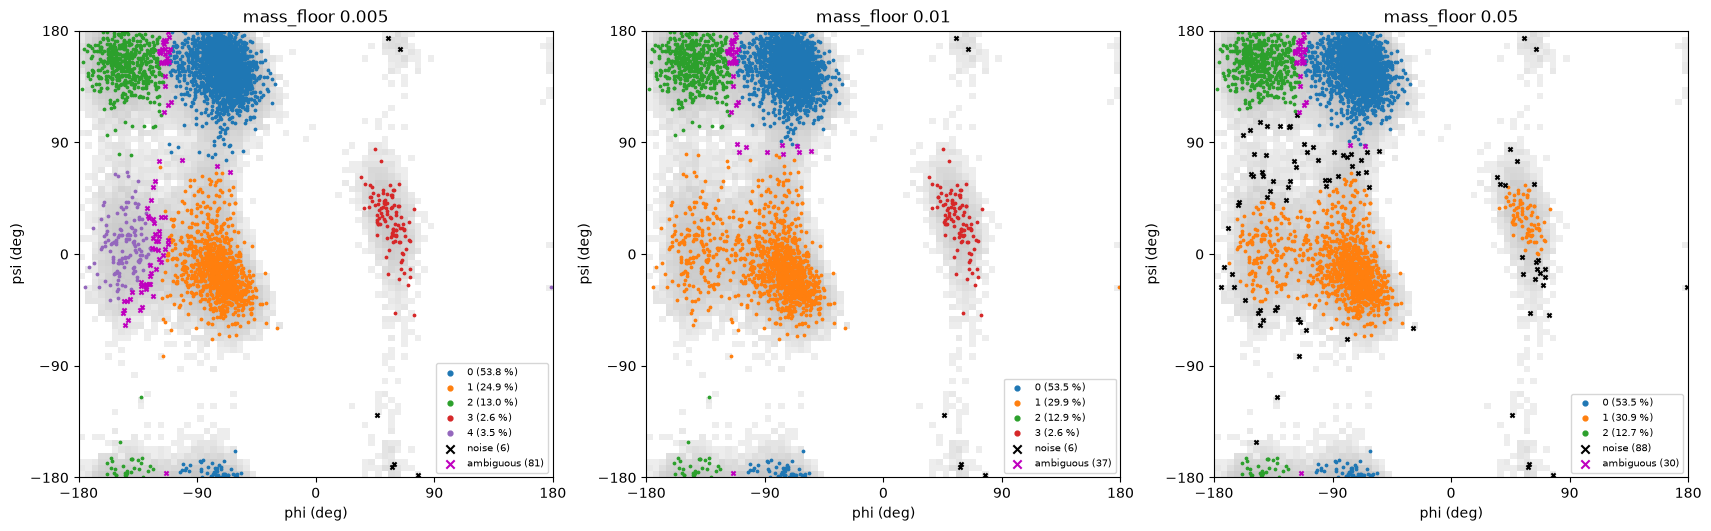

,mass_floor,clusters,masses (%),noise -2 (%),ambiguous -1 (%),min_cluster_size,min_samples
0,0.005,5,"[53.8, 24.9, 13.0, 2.6, 3.5]",0.15,2.02,20,40
1,0.010,4,"[53.5, 29.9, 12.9, 2.6]",0.15,0.92,40,40
2,0.050,3,"[53.5, 30.9, 12.7]",2.20,0.75,200,40


In [4]:
floors = (0.005, 0.01, 0.05)
fits = {v: fit(mass_floor=v, min_samples=40) for v in floors}
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), layout="constrained")
for ax, (v, f) in zip(axes, fits.items()):
    rama(ax, f, f"mass_floor {v}")
plt.show()
pd.DataFrame([{"mass_floor": v, **populations(f)} for v, f in fits.items()])

At 0.5 % the left shoulder of the alpha-R region (phi near -150, psi near 0) is a cluster of its own. At 5 %
alpha-L, 2.6 % of the frames, is below the floor and is not a cluster. Its frames are not all noise, though:
about 1 point of its 2.6 joins the alpha-R cluster (orange, which grows from 29.9 to 30.9 %), across the
empty region at phi near 0; the rest is noise, with part of alpha-R's left shoulder. A cluster under the floor is
absorbed into its parent in HDBSCAN's condensed tree, and nothing requires that parent to be connected in
the torsion space you look at.

## 3. `min_samples`: the density estimate

HDBSCAN's density at a frame is set by its **core distance**, the distance to its `min_samples`-th
neighbour. A small `min_samples` resolves fine structure and calls more of it clusters; a large one
smooths. The default ties it to the frame count, `round(0.01 n)`; `min_samples_fraction` sets the
fraction instead, and `min_samples` an absolute count.

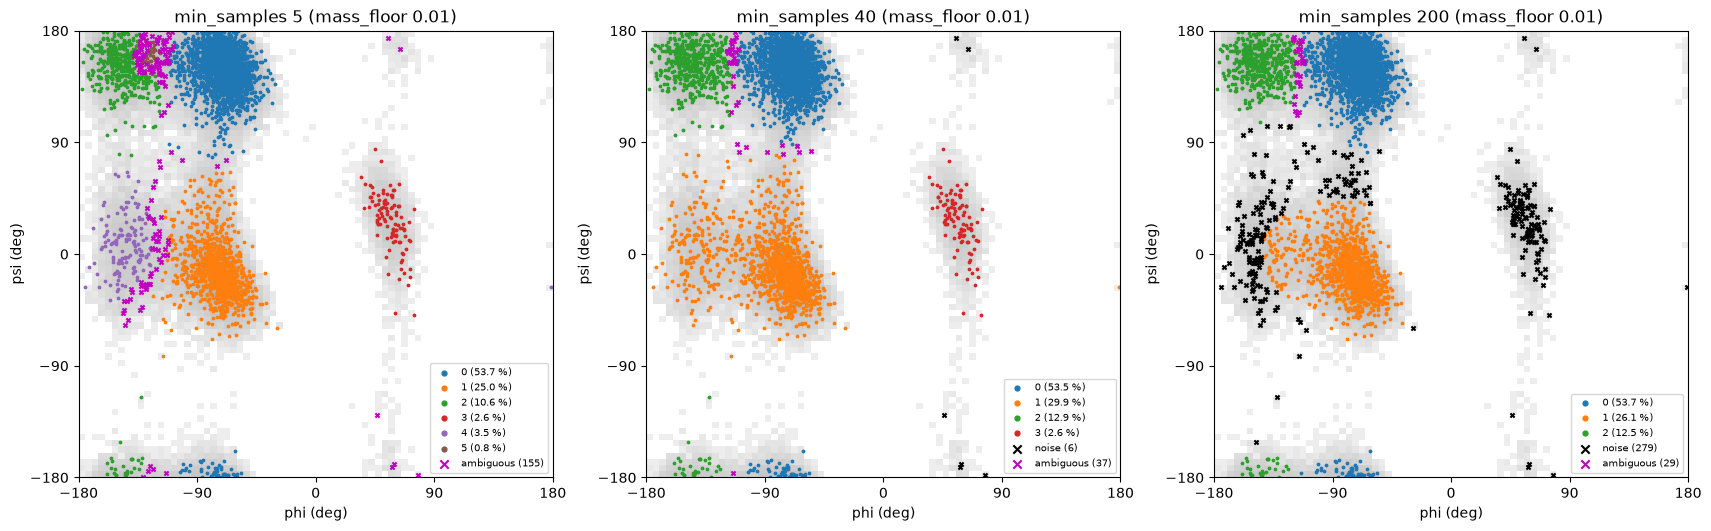

,min_samples,clusters,masses (%),noise -2 (%),ambiguous -1 (%),min_cluster_size
0,5,6,"[53.7, 25.0, 10.6, 2.6, 3.5, 0.8]",0.00,3.88,40
1,10,5,"[53.4, 24.8, 13.0, 2.6, 3.9]",0.18,2.20,40
2,25,5,"[53.7, 25.0, 13.0, 2.6, 3.5]",0.15,1.98,40
3,40,4,"[53.5, 29.9, 12.9, 2.6]",0.15,0.92,40
4,100,4,"[53.6, 29.8, 13.0, 2.5]",0.22,0.90,40
5,200,3,"[53.7, 26.1, 12.5]",6.98,0.73,40


In [5]:
counts = (5, 10, 25, 40, 100, 200)
fits = {v: fit(min_samples=v) for v in counts}
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), layout="constrained")
for ax, v in zip(axes, (5, 40, 200)):
    rama(ax, fits[v], f"min_samples {v} (mass_floor 0.01)")
plt.show()
pd.DataFrame([{"min_samples": v, **populations(f)} for v, f in fits.items()])

Six clusters at 5, four at 40 and 100, three at 200, where alpha-L is smoothed into noise. **Tying `min_samples`
to `n` has a cost**: at 300 000 frames the default is 3000, which smooths away a marginal basin, so on a large
ensemble an absolute `min_samples` (25 restores the behaviour of a small fit) is the knob to turn.

**`min_samples` is pinned separately from the floor.** sklearn lets `min_samples` follow `min_cluster_size`,
so raising the floor alone would change the density estimate instead of filtering clusters out of a
fixed one. Measured here, a 5 % floor:

In [6]:
pd.DataFrame([{"rule": "pinned (min_samples 40)", **populations(fit(mass_floor=0.05))},
              {"rule": "following (min_samples = min_cluster_size = 200)", **populations(fit(mass_floor=0.05, min_samples=200))}])

,rule,clusters,masses (%),noise -2 (%),ambiguous -1 (%),min_cluster_size,min_samples
0,pinned (min_samples 40),3,"[53.5, 30.9, 12.7]",2.20,0.75,200,40
1,following (min_samples = min_cluster_size = 200),3,"[53.7, 26.1, 12.5]",6.98,0.73,200,200


The same three basins; with `min_samples` following the floor, 7 % of the frames become noise instead of 2 %,
taken mostly from alpha-R.
On 15 000 hot c(RGDfV) frames a 5 % floor with `min_samples` following turned every frame into noise; pinned, it
returned the two clusters above 5 %.

## 4. `allow_single_cluster`

With it False (the default, as in sklearn) HDBSCAN's excess-of-mass selection may not choose the root of
its condensed tree, so **a unimodal ensemble cannot come back as one state**: it is split, with a
plausible mass split and nothing saying one state was never a candidate. With it True a multi-state
ensemble can collapse into one cluster. On the full ALA ensemble the flag changes nothing. On the
frames of the alpha-R region alone (phi < 0, psi between -100 and 80 degrees), which the default fit on all
frames calls one cluster:

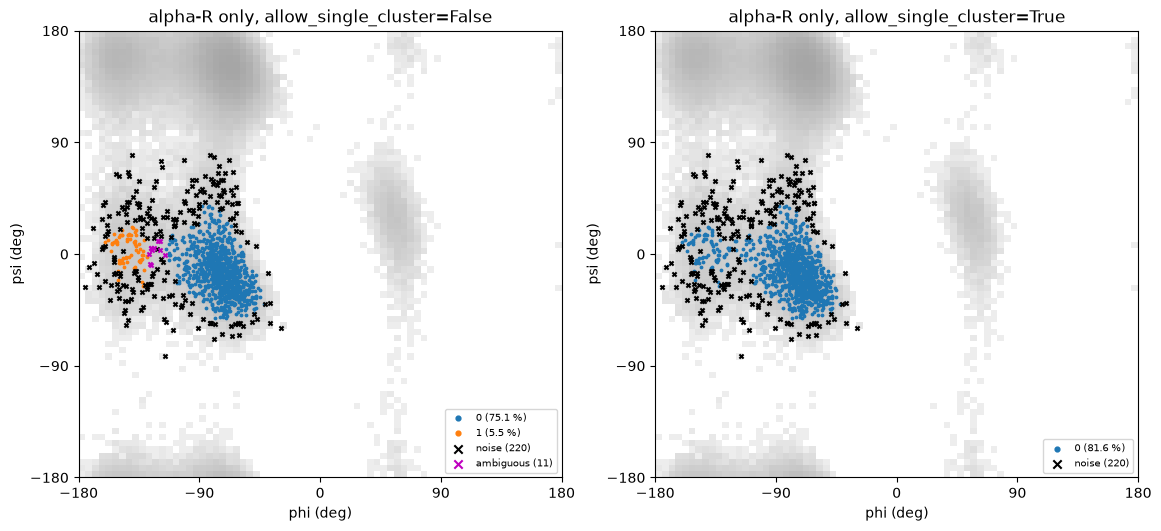

,frames,allow_single_cluster,clusters,masses (%),noise -2 (%),ambiguous -1 (%),min_cluster_size,min_samples
0,all 4000,False,4,"[53.5, 29.9, 12.9, 2.6]",0.15,0.92,40,40
1,all 4000,True,4,"[53.5, 29.9, 12.9, 2.6]",0.15,0.92,40,40
2,"alpha-R only, 1194",False,2,"[75.1, 5.5]",18.43,0.92,12,12
3,"alpha-R only, 1194",True,1,[81.6],18.43,0.00,12,12


In [7]:
alpha = SUB[(tors[:, 0] < 0) & (tors[:, 1] > np.radians(-100)) & (tors[:, 1] < np.radians(80))]
rows = [{"frames": "all 4000", "allow_single_cluster": flag, **populations(fit(allow_single_cluster=flag))}
        for flag in (False, True)]
alpha_fits = {flag: fit(alpha, allow_single_cluster=flag) for flag in (False, True)}
rows += [{"frames": f"alpha-R only, {len(alpha)}", "allow_single_cluster": flag, **populations(f)}
         for flag, f in alpha_fits.items()]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.2), layout="constrained")
for ax, (flag, f) in zip(axes, alpha_fits.items()):
    rama(ax, f, f"alpha-R only, allow_single_cluster={flag}", rows=alpha)
plt.show()
pd.DataFrame(rows)

False has to return at least two clusters, and cuts off the left shoulder (5.5 %); True returns one. The data
do not decide between them: the flag does. With False, `summary()` says so (`single_cluster_excluded_by_construction`, and a
caveat). The default was True from 2026-10-01 to 2026-10-22 and was changed back because on a ligand's
torsional states the opposite error mattered: c(RGDfV) with 19 torsion columns gave one cluster with it
True and two with it False. If your ensemble may be one state, pass `True` and check the answer against
the marginals.

## 5. Assigning frames: `k` and `min_vote_fraction`

After the fit, every frame (fitted or not) is classified by its `k` nearest **clustered** training frames
under the same distance, itself excluded. It joins the winning cluster when

```text
n_winner / k_effective >= min_vote_fraction        (equality accepted; 18 of 20 assigns, 17 of 20 does not)
```

`k_effective` is `k`, or the number of eligible training frames when there are fewer, reported per frame
(`fit.k_effective_`). Neighbours at equal distance are ordered by index. Two codes for an unassigned frame:

* **-2, density noise**: the frame's `min_samples`-th neighbour is farther than that of any clustered
  training frame. It takes precedence.
* **-1, ambiguous**: the vote is below the threshold. This describes the sample around the frame; it is
  **not** evidence of a free-energy barrier.

`noise_mass_`, `ambiguous_mass_` and their sum `unassigned_mass_` are reported separately.

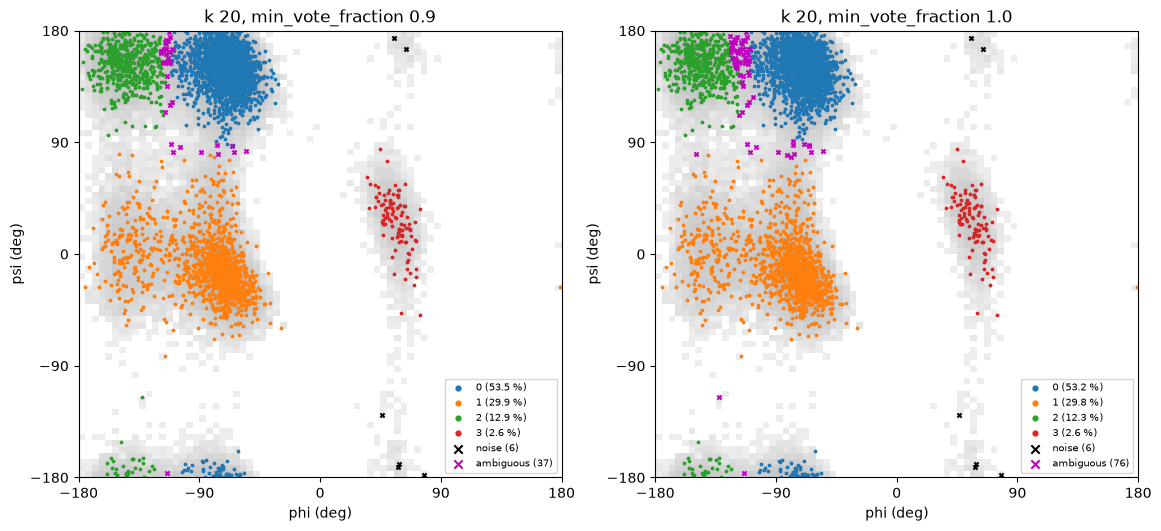

,k,min_vote_fraction,clusters,masses (%),noise -2 (%),ambiguous -1 (%),min_cluster_size,min_samples
0,20,0.9,4,"[53.5, 29.9, 12.9, 2.6]",0.15,0.92,40,40
1,20,0.6,4,"[53.8, 30.0, 13.3, 2.6]",0.15,0.10,40,40
2,20,1.0,4,"[53.2, 29.8, 12.3, 2.6]",0.15,1.90,40,40
3,5,0.9,4,"[53.5, 30.0, 12.9, 2.6]",0.15,0.70,40,40
4,50,0.9,4,"[53.1, 29.8, 12.6, 2.6]",0.15,1.68,40,40


In [8]:
votes = {(20, 0.9): default, (20, 0.6): fit(min_vote_fraction=0.6), (20, 1.0): fit(min_vote_fraction=1.0),
         (5, 0.9): fit(k=5), (50, 0.9): fit(k=50)}
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.2), layout="constrained")
for ax, key in zip(axes, ((20, 0.9), (20, 1.0))):
    rama(ax, votes[key], f"k {key[0]}, min_vote_fraction {key[1]}")
plt.show()
pd.DataFrame([{"k": k, "min_vote_fraction": v, **populations(f)} for (k, v), f in votes.items()])

The vote moves frames only at the borders between clusters: the ambiguous frames (magenta) sit between the
beta and PPII regions and along psi near 90 degrees, above alpha-R. Unanimity (`1.0`) doubles the ambiguous mass; a looser vote assigns almost every
frame. Neither changes which clusters exist: that is the fit's business.

`min_vote` (a MARGIN, with `k` 15) is the legacy rule and is refused unless `vote_rule="legacy-margin"`; a margin
is never reinterpreted as a fraction.

## 6. More frames than the matrix allows: `resampling`

`d_sym` is a minimum over relabellings and is not Euclidean in any fixed embedding, so it is handed to
HDBSCAN as an **exact dense matrix** (`metric="precomputed"`): `8 n²` bytes per copy, 122 MiB at 4000 frames,
and sklearn holds about three. Above `max_precomputed_frames` (10 000) the fit refuses and names the
subset route:

In [9]:
try:
    fit(np.arange(len(every)))
except Exception as error:
    print(type(error).__name__, ":", str(error).splitlines()[0][:300])

PrecomputedMemoryGuard : the symmetry-aware distance is fitted as an EXACT dense matrix: 100000 frames need 76294 MiB per copy, and HDBSCAN's precomputed path holds about three. That exceeds max_precomputed_frames=10000. Fit a subset with resampling=N (N <= 10000; frames are drawn in proportion to the weights, and EVERY fra


`resampling=N` draws N frames (in proportion to the weights, Madow systematic, without replacement:
duplicate frames would give zero distances and a core distance of zero), fits them, and classifies every
frame with the same distance and vote. The same distance serves the fit, the vote, the density-noise
threshold and the medoid tie-break of `representatives()`, and it is never swapped to make a fit cheaper.

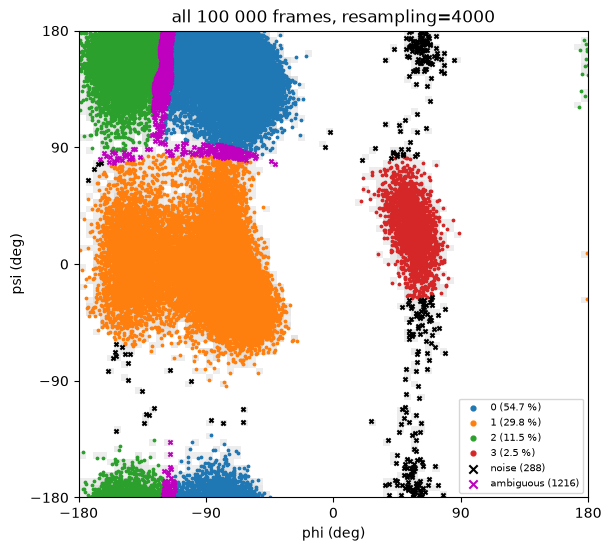

,frames,clusters,masses (%),noise -2 (%),ambiguous -1 (%),min_cluster_size,min_samples
0,"every 25th, 4000",4,"[53.5, 29.9, 12.9, 2.6]",0.15,0.92,40,40
1,"all 100 000, resampling=4000",4,"[54.7, 29.8, 11.5, 2.5]",0.29,1.22,40,40


In [10]:
ALL = np.arange(len(every))
big = fit(ALL, resampling=4000)
fig, ax = plt.subplots(figsize=(6, 5.4), layout="constrained")
rama(ax, big, "all 100 000 frames, resampling=4000", rows=ALL)
plt.show()
pd.DataFrame([{"frames": "every 25th, 4000", **populations(default)},
              {"frames": "all 100 000, resampling=4000", **populations(big)}])

The same four clusters with masses within 1.5 points of the strided fit. `seed` sets the draw.

**Frame weights.** HDBSCAN cannot weight its density estimate: a core distance is a rank statistic, so
there is no `sample_weight` to pass. With non-uniform `weights` and `resampling=False` only the
POPULATIONS are reweighted and the partition is fitted on the sampled ensemble; `resampling=N` fits the
target distribution itself.

## 7. Which torsions

The density is estimated in the space of the torsions passed, and that choice moves the answer more
than any parameter above.

In [11]:
phi_only = fit(cols=(0,))
pd.DataFrame([{"torsions": "phi, psi", **populations(default)}, {"torsions": "phi only", **populations(phi_only)}])

,torsions,clusters,masses (%),noise -2 (%),ambiguous -1 (%),min_cluster_size,min_samples
0,"phi, psi",4,"[53.5, 29.9, 12.9, 2.6]",0.15,0.92,40,40
1,phi only,3,"[78.9, 17.9, 2.8]",0.00,0.38,40,40


On phi alone alpha-R and PPII, both near phi -70 degrees, are one cluster, and the cluster at phi near -150 holds
beta together with the left shoulder of alpha-R. The opposite happens too: on c(RGDfV)
adding nearly uniform side-chain torsions to the backbone dilutes the density that separates the
backbone conformers (the [c(RGDfV) tutorial](https://csy0000.github.io/MD-tools/tutorial/rgdfv/analysis/clustering/) has the table).

## What a fit does not claim

* **A cluster is a density basin, NOT a metastable state.** Two density peaks separated by a sampled
  region are two clusters whatever the barrier between them, and a long-lived but diffuse state may be
  one cluster or none.
* **Seed agreement is precision, not accuracy.** `draw_agreement_` says the cluster count was stable under
  resampling, not that a small state was seen.
* **Structural, not thermodynamic.** A graph automorphism says two configurations are one conformer under
  another naming; it does not make their populations equal. Declare an atom-specific restraint or a
  REST2 region covering one side with `broken_by=[...]`; it is recorded in the summary.

## After one fit: `refine_by_rmsd` and `hierarchical_clustering`

Both take a fitted symmetry-first `THDBSCAN` and the coordinates. The thermodynamic cut of the second is the
ancestor of [torsion partitioning](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/torsion-partitioning/), which drops HDBSCAN altogether.

### `refine_by_rmsd`: splitting a cluster that is too wide in space

A torsional cluster is a density basin in torsion space, and nothing in the fit looks at how far apart
its members are in Cartesian space. HDBSCAN's condensed tree can keep two sub-populations together
(a parent more stable than its children), and a small torsion difference can move many atoms. The
[symmetry-corrected RMSD](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/torsion-preprocessing/#9-symmetry-corrected-rmsd) within the cluster says when that has happened, and `refine_by_rmsd` acts on
it:

```python
fit = t_hdbscan(torsions, molecule=mol, torsion_definitions=defs,
                coordinates=traj, atom_mapping=mapping).fit()
refined = fit.refine_by_rmsd(traj)                   # cutoff=2.0 A, an mdtraj.Trajectory is read as nm
refined["labels"], refined["cluster_mass"], refined["tree"]
```

For each cluster the mean pairwise RMSD of its frames is compared with `cutoff` (default **2 A**). A
wide cluster is fitted again on its own frames, with the fit's own settings and
`allow_single_cluster=False`, and the split is kept only if the refit returns at least two clusters.
Each child is then examined the same way. The loop ends at a node that is inside the cutoff, smaller
than `min_frames` (default `2 k`, 40), at `max_depth` (4), or where the refit finds no second cluster;
every accepted split shrinks the frames per node, so it is finite. `tree` records one entry per node
examined (frames, RMSD mean and std, and which of those four ended it).

* **Atoms measured.** Every heavy atom of the molecule (`moved_atoms`): a torsion turns everything
  attached beyond its central bond, so the four atoms that define it understate what it displaces.
  `atoms='quadruplets'` measures only the defining atoms, closed under the molecular symmetry
  (`torsion_atoms`), and a list replaces them with a union of symmetry orbits. Hydrogens are not
  measured, so two clusters that differ only in a hydroxyl proton (paracetamol A and B) are neither
  merged nor split by this.
* **The cutoff is the guard.** The refit forbids a single cluster, so a cluster wider than the cutoff
  is divided whenever the refit finds a density structure in it, including a single broad basin: a
  paracetamol basin of mean RMSD 0.064 A was cut into three at a cutoff of 0.05 A and left whole at
  0.2 A. Choose the cutoff as the size of a difference you would call a different structure.
* **A mean can hide a minority.** A cluster that is 90 % one structure and 10 % another 4 A away has a
  mean pairwise RMSD of about 0.7 A. `statistic=0.95` (a quantile) tests the tail instead.
* **Frames the refit drops.** A frame the refit calls noise or ambiguous takes that code and leaves the
  cluster; a split moves mass out of a cluster and never into one it was not part of.
* **What it does not change.** The fit, its `predict` and its vote are untouched: new frames are still
  classified by the first-level partition. The returned labels are for the frames the fit was made from.
* **Tested on** a synthetic paracetamol ensemble (cis and trans amide, merged into one cluster by hand
  because the fit separates them) at cutoffs of 0.03-0.3 A, the scale of that molecule. Not run on
  c(RGDfV) or any registered trajectory; whether 2 A is the right cutoff for a cyclic peptide is not
  established here.

### `hierarchical_clustering`: two rounds, a thermodynamic cut, bits, mass order

One HDBSCAN fit can keep two basins together (a parent more stable than its children), and lowering
`min_samples` to separate them mostly produces noise clusters. `hierarchical_clustering` takes a
fitted symmetry-first `THDBSCAN` and applies, on every node (the whole ensemble first):

```python
from md_tools.analysis import t_hdbscan, hierarchical_clustering, plot_hist, show_compound

fit = t_hdbscan(torsions, molecule=mol, torsion_definitions=defs,
                coordinates=traj, atom_mapping=mapping, mass_floor=0.01).fit()
result = hierarchical_clustering(fit, traj, gauge=("t3 aryl-CO", np.pi),
                                 torsion_null_test=40, kT_cut=1.6)
result["labels"], result["n_clusters"], result["rounds"], result["cuts"], result["bits"]
plot_hist(result, torsion_show="all", n_cluster=10, kind="free_energy")
show_compound(result["molecule"], result["quads"], torsion_enumerate=True)
```

1. **Round 1:** HDBSCAN on every torsion.
2. **Round 2:** a torsion on which no pair of round-1 clusters differs is dropped and HDBSCAN is fitted
   again on the rest. "Differs" is a permutation test: the two clusters' frames are pooled and
   reshuffled to the same sizes `torsion_null_test` times (default 40), and the observed circular W2
   distance must exceed the 95th percentile of the reshuffled ones. The percentile of 40 shuffles is
   noisy: a torsion whose observed W2 is close to it can flip with `seed`. A torsion that a symmetry
   operation moves together with a kept torsion is never dropped; without it the operation maps one
   state onto the other (the ring flip carries the aryl-CO and the aryl-N torsion). `result["rounds"]`
   keeps the observed and null W2 of every pair and torsion, what was dropped, and both cluster counts.
3. **Thermodynamic cut.** On the circular free-energy profile of one torsion in a node (72 bins, F in kT,
   an empty bin set to `max(F) + 1`), cut 1 is the centre of the highest plateau and cut 2 is any bin
   whose F exceeds the lowest point of the smaller arc by at least `kT_cut` (default **1.6 kT**, 0.95
   kcal/mol at 300 K; the rule needs no temperature). Both arcs must hold at least `mass_floor` of all
   frames (default 1 %). Two cuts are needed on a circle: a low route through a shallow third well means
   no split. The cut is taken directly only if that torsion is the only one with such a pair, because the
   marginal profile has integrated every other dimension: an empty cut bin means no density on the whole
   hyperplane, so nothing connects the arcs. Frames within one bin of a **non-empty** cut are marked
   ambiguous.
4. **Bits.** For each torsion, clusters are grouped by pairwise W2 (complete linkage, 20 degrees), the
   groups are numbered from 0 by the frames they own, and clusters with identical bit vectors are merged
   (`merge_by_bits=False` keeps the table and merges nothing). The 20 degrees is below the W2 noise floor
   of broad or multimodal profiles, so it is a coarse grouping, not a statistical test.
5. **Numbering** is by cluster mass, largest first. Neighbouring numbers are not similar structures.

Frames in no leaf get `NOISE_LABEL`, frames beside a non-empty cut `AMBIGUOUS_LABEL`. `result["rmsd"]` is
the heavy-atom symmetry-corrected inter- and intra-cluster RMSD in the final numbering.

* **Observed on one trajectory, not a test of the method.** Folic acid dianion, REST2 state 0, 100 ns at
  stride 10 (5000 frames), 14 torsions (nine heavy-atom, five polar-hydrogen): 12 clusters, 53 % of the
  frames unassigned (32 of them ambiguous), three cuts, all on the CH2-C6 torsion, and no bit merge.
  Wells under 1 % of the frames stay inside their cluster: a floor sets what is a cluster. That
  trajectory is not registered, so the numbers cannot be reproduced from this repository.
* **A cluster is a density basin, not a metastable state;** one trajectory gives no resampling stability,
  and with a few dozen frames in a node the histogram rules are noisy.
* **Not done:** frame weights (refused), a cache of the per-torsion distance terms (exact, but 0.86 s to
  build against 0.07 s to recompute at 1000 frames), and detection of sub-structure below the floor.

## Migrating an existing call

| before | now |
|---|---|
| `t_hdbscan(tors)` | refused: pass `molecule`, `torsion_definitions` (and `coordinates`, `atom_mapping`), or `symmetry=False` |
| `t_hdbscan(tors)` for the old numbers | `t_hdbscan(tors, symmetry=False, vote_rule="legacy-margin")` |
| `min_vote=0.9` (a margin, k = 15) | refused unless `vote_rule="legacy-margin"`; the threshold is `min_vote_fraction` (k = 20) |
| `summary()["min_vote"]` | `summary()["vote"]` (`rule`, `k`, `k_effective_min/max`, `min_vote_fraction`) |
| `noise_mass_` (both codes) | `noise_mass_` is density noise only; add `ambiguous_mass_`, or read `unassigned_mass_` |
| name `"barrier"` for -1 | `"ambiguous"` (`BARRIER_LABEL` is kept as an alias of `AMBIGUOUS_LABEL`) |
| `representative_by_vote(fit)` | unchanged; it uses the fit's own distance and vote (`fit.representatives()`) |
| `multiplicities=[...]` with symmetry | refused: the symmetric distance replaces per-torsion folding |
| cluster, then `TorsionSymmetry` merge | the default route needs no merge; the merge remains for the legacy route ([Analysis](https://csy0000.github.io/MD-tools/openmm_methods/analysis/#t_symmetry)) |